<a href="https://colab.research.google.com/github/FernandoMR10/Sistemas-Inteligentes-MRF/blob/main/Tarea_02_Introducci%C3%B3n_a_visi%C3%B3n_computacional_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install importlib_resources

In [3]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay

In [4]:
# Verificamos y configuraramos la GPU
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)
else:
    print("No se detectó GPU. Se usará la CPU.")

1 Physical GPUs, 1 Logical GPUs


In [5]:
# 1. Cargamos Fashion-MNIST con tensorflow_datasets
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.KLAAJQ_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.KLAAJQ_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.


In [6]:
# 2. Función para normalizar los píxeles (de 0 a 1)
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Aplicamos la normalización
train_ds = train_ds.map(normalize)
test_ds = test_ds.map(normalize)

# 3. Clases de Fashion-MNIST
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [7]:
# 4. Función para graficar el aprendizaje
def plot_learning_curve(history, titulo=""):
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title(f'Accuracy {titulo}')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'Loss {titulo}')
    plt.legend()

    plt.tight_layout()
    plt.show()

--- CONFIGURACIÓN 1: BÁSICA ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.8224 - loss: 0.4946 - val_accuracy: 0.8447 - val_loss: 0.4336
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8670 - loss: 0.3659 - val_accuracy: 0.8592 - val_loss: 0.3913
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.8791 - loss: 0.3299 - val_accuracy: 0.8648 - val_loss: 0.3689
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8875 - loss: 0.3061 - val_accuracy: 0.8722 - val_loss: 0.3548
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8945 - loss: 0.2874 - val_accuracy: 0.8728 - val_loss: 0.3515
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8991 - loss: 0.2713 - val_accuracy: 0.8785 - val_loss: 0.3446
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9029 - loss: 0.2584 - val_accuracy: 0.8789 - val_loss: 0.3404
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9082 - loss: 0.2462 

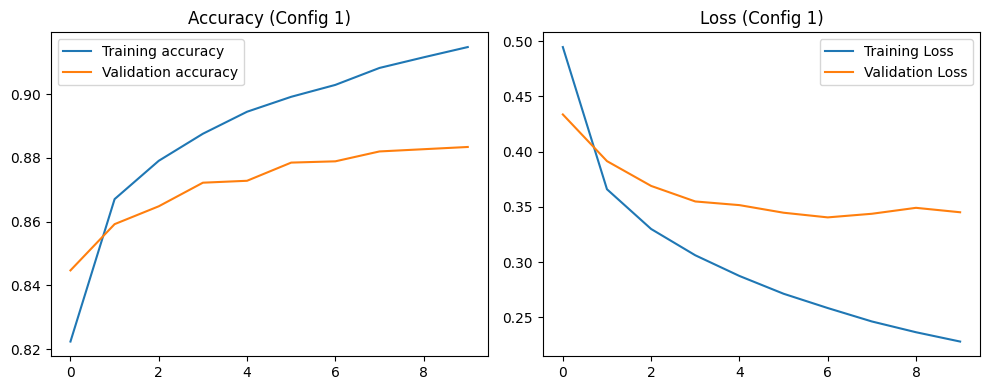

In [8]:
print("--- CONFIGURACIÓN 1: BÁSICA ---")
model1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=64, activation="relu"),
    tf.keras.layers.Dense(units=10, activation="softmax")
])

model1.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model1.summary()

history1 = model1.fit(train_ds, epochs=10, validation_data=test_ds)
plot_learning_curve(history1, "(Config 1)")

--- CONFIGURACIÓN 2: PROFUNDA ---
Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 3ms/step - accuracy: 0.8271 - loss: 0.4792 - val_accuracy: 0.8434 - val_loss: 0.4243
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8663 - loss: 0.3613 - val_accuracy: 0.8598 - val_loss: 0.3887
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8798 - loss: 0.3264 - val_accuracy: 0.8614 - val_loss: 0.3907
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8875 - loss: 0.3018 - val_accuracy: 0.8682 - val_loss: 0.3687
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8944 - loss: 0.2823 - val_accuracy: 0.8771 - val_loss: 0.3653
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8992 - loss: 0.2674 - val_accuracy: 0.8789 - val_loss: 0.3571
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9043 - loss: 0.2548 - val_accuracy: 0.8777 - val_loss: 0.3643
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - 

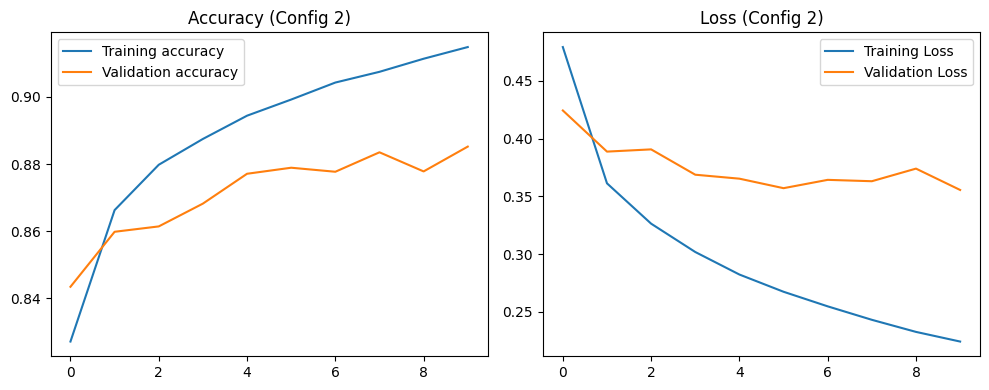

In [9]:
print("--- CONFIGURACIÓN 2: PROFUNDA ---")
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=256, activation="relu"),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=64, activation="relu"),
    tf.keras.layers.Dense(units=10, activation="softmax")
])

model2.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history2 = model2.fit(train_ds, epochs=10, validation_data=test_ds)
plot_learning_curve(history2, "(Config 2)")

--- CONFIGURACIÓN 3: ESPACIO LATENTE 2D ---
Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.6531 - loss: 1.0329 - val_accuracy: 0.7569 - val_loss: 0.7599
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7957 - loss: 0.6646 - val_accuracy: 0.8019 - val_loss: 0.6661
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8199 - loss: 0.5810 - val_accuracy: 0.8165 - val_loss: 0.6195
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8322 - loss: 0.5344 - val_accuracy: 0.8242 - val_loss: 0.5954
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8422 - loss: 0.5006 - val_accuracy: 0.8274 - val_loss: 0.5789
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8503 - loss: 0.4736 - val_accuracy: 0.8310 - val_loss: 0.5665
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8602 - loss: 0.4482 - val_accuracy: 0.8366 - val_loss: 0.5594
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3

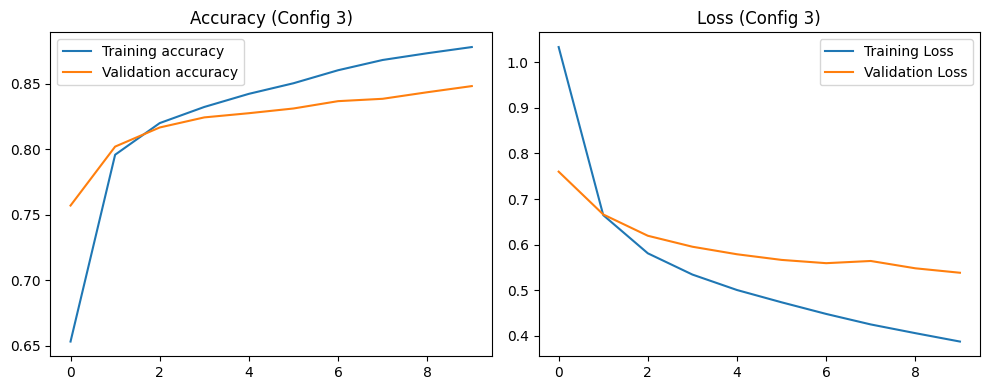

In [10]:
print("--- CONFIGURACIÓN 3: ESPACIO LATENTE 2D ---")
model3 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units=128, activation="relu"),
    tf.keras.layers.Dense(units=2, activation="linear", name="rep_2d"), # Capa para graficar 2D
    tf.keras.layers.Dense(units=10, activation="softmax")
])

model3.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history3 = model3.fit(train_ds, epochs=10, validation_data=test_ds)
plot_learning_curve(history3, "(Config 3)")

#### Se probaron 3 arquitecturas distintas. La Configuración 1 (básica) y la Configuración 2 (más profunda) alcanzaron un accuracy cercano al 88%. La Configuración 3 incluyó un cuello de botella de 2 neuronas para extraer el espacio latente.

94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


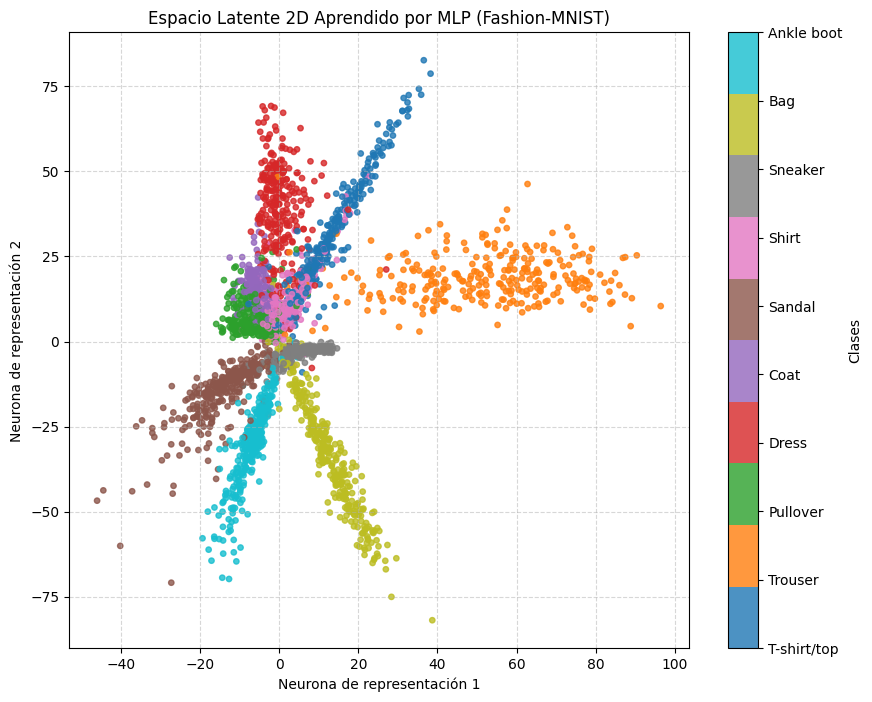

In [11]:
# Usamos el modelo 3 que tiene la capa "rep_2d"
extractor = tf.keras.Model(
    inputs=model3.inputs,
    outputs=model3.get_layer("rep_2d").output
)

# Tomamos una muestra de 3000 imágenes para no saturar la gráfica
x_visual = []
y_visual = []
for images, labels in test_ds.unbatch().take(3000):
    x_visual.append(images.numpy())
    y_visual.append(labels.numpy())

x_visual = np.array(x_visual)
y_visual = np.array(y_visual)

# Predecimos los puntos en 2D
puntos2d = extractor.predict(x_visual)

# Graficamos
plt.figure(figsize=(10, 8))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_visual,
    cmap="tab10",
    s=15,
    alpha=0.8,
)
plt.title("Espacio Latente 2D Aprendido por MLP (Fashion-MNIST)")
plt.xlabel("Neurona de representación 1")
plt.ylabel("Neurona de representación 2")
cbar = plt.colorbar(scatter_plot, ticks=range(10), label="Clases")
cbar.ax.set_yticklabels(class_names)
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

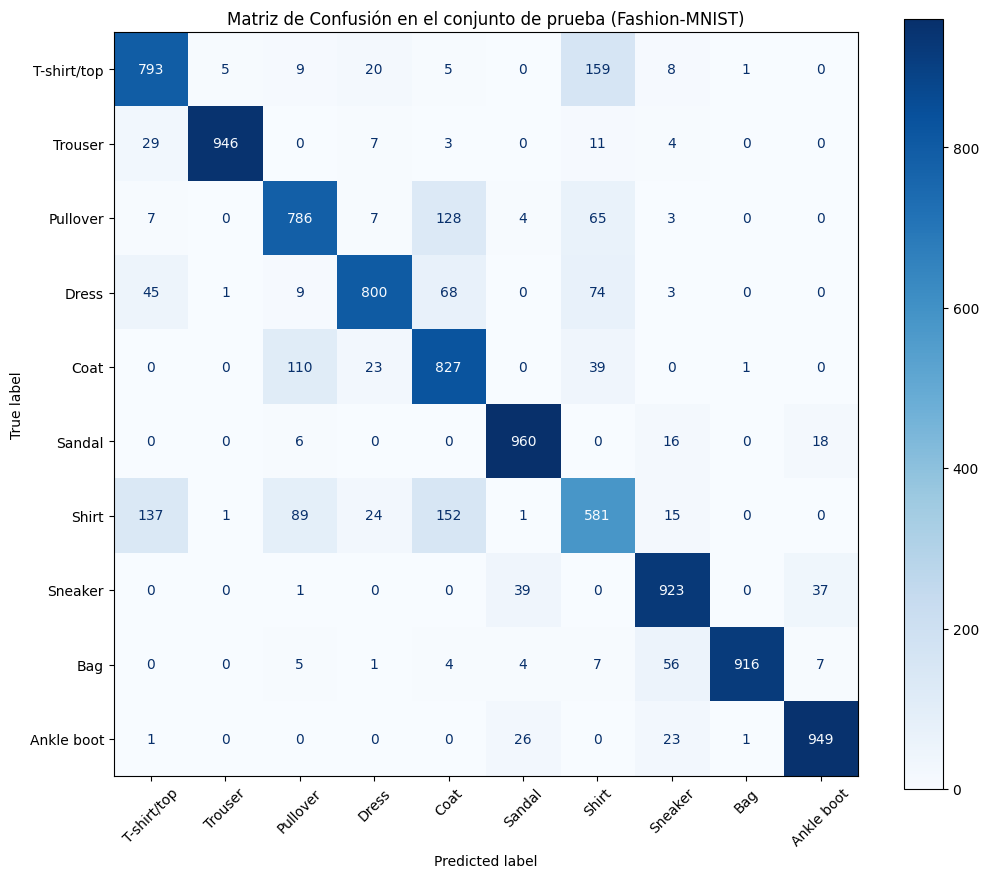

In [12]:
# Evaluamos las predicciones totales del modelo 3
y_true = []
y_pred = []

for images, labels in test_ds:
    preds = model3.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    ax=ax,
    xticks_rotation=45
)
plt.title("Matriz de Confusión en el conjunto de prueba (Fashion-MNIST)")
plt.grid(False)
plt.show()

#### La matriz muestra una diagonal principal fuerte. La mayor parte de los errores ocurren entre prendas de vestir parecidas, como Shirt confundidas con T-shirts o Coats.